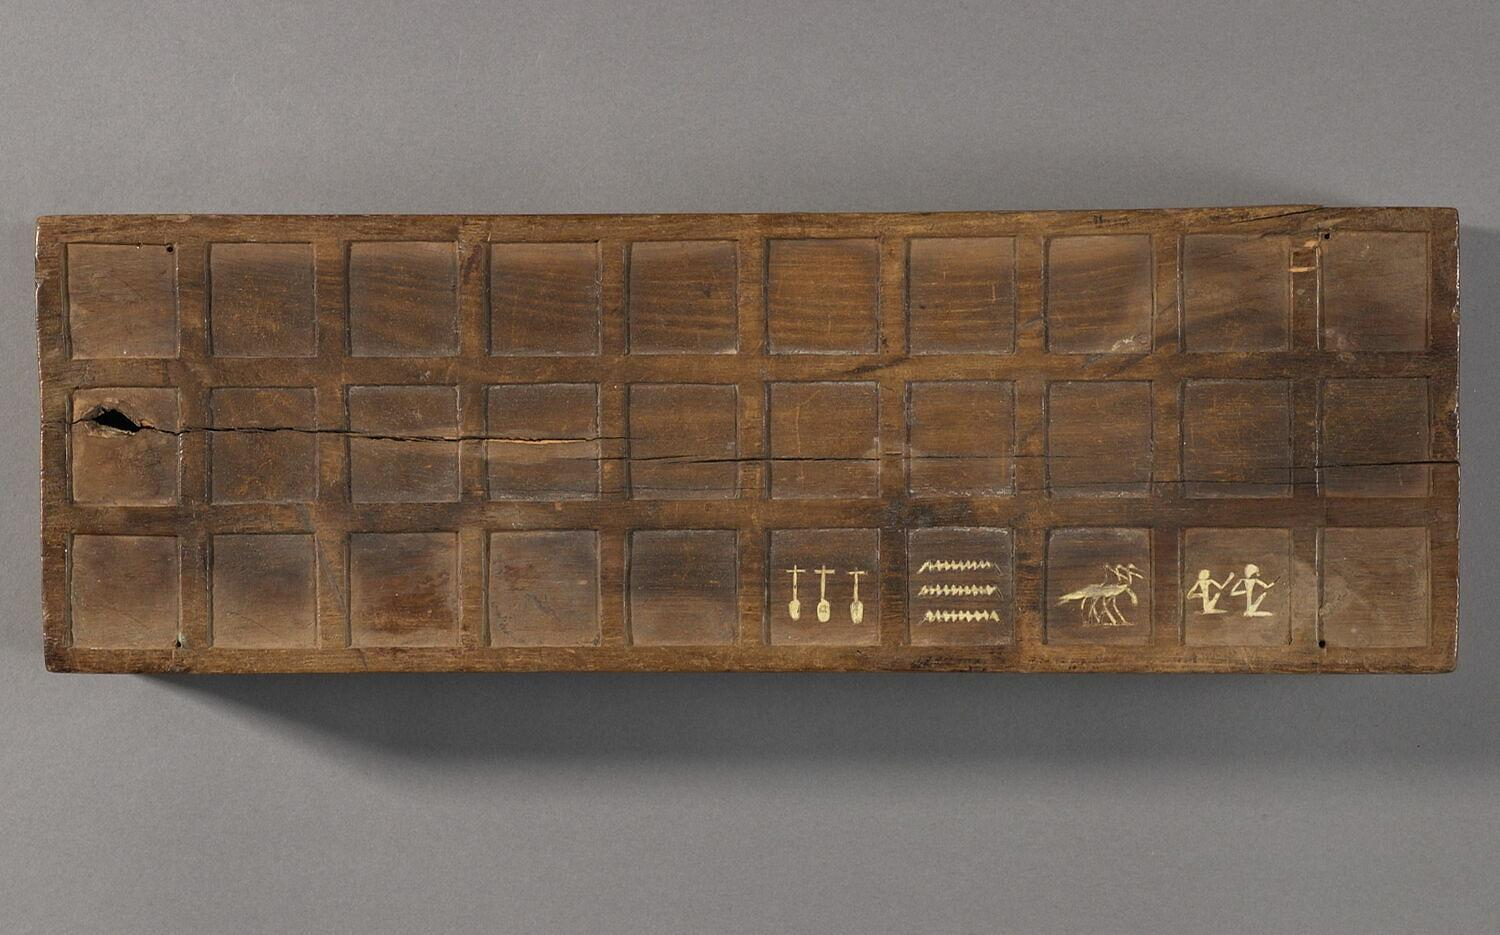

In [ ]:

import math
import os
import random
import sys
from array import array

import pygame

# إعداد الصوت لازم يتعمل قبل pygame.init
try:
    pygame.mixer.pre_init(22050, -16, 1)
except Exception:
    pass
pygame.init()

# =====================================================================
#                              الإعدادات
# =====================================================================
SCREEN_WIDTH = 1200
SCREEN_HEIGHT = 750
try:
    screen = pygame.display.set_mode(
        (SCREEN_WIDTH, SCREEN_HEIGHT), pygame.SCALED | pygame.RESIZABLE
    )
except Exception:
    screen = pygame.display.set_mode((SCREEN_WIDTH, SCREEN_HEIGHT))
pygame.display.set_caption("Royal Egyptian Senet -> By -> Eng:Mohanad Mahmoude Mostafa")
# أيقونة نافذة اللعبة (ضع me.ico بجانب ملف اللعبة)
try:
    pygame.display.set_icon(pygame.image.load(asset_path("me.ico")))
except Exception as e:
    print("تعذر تحميل أيقونة me.ico:", e)

GOLD = (212, 175, 55)
BLUE = (20, 35, 60)
DARK_PANEL = (15, 25, 45)
GREEN = (80, 255, 120)
WHITE = (255, 255, 255)

# التوقيتات (بالملي ثانية)
HOP_MS = 210       # الوقت اللي القطعة بتاخده عشان تعدّي خانة واحدة
ROLL_MS = 800      # مدة لفّة النرد
AI_DELAY = 700     # تأخير الكمبيوتر قبل ما يتحرك
PASS_MS = 1300     # الوقت اللي بيفضل ظاهر لما الدور بيعدّي


def now_ms():
    return pygame.time.get_ticks()


# =====================================================================
#                          تحميل الصور
# =====================================================================
def asset_path(name):
    """بيدوّر على الملف جنب الكود الأول، وبعدين في الفولدر الحالي."""
    base = getattr(sys, "_MEIPASS", None)
    if base is None:
        try:
            base = os.path.dirname(os.path.abspath(__file__))
        except NameError:
            base = os.getcwd()
    candidate = os.path.join(base, name)
    return candidate if os.path.exists(candidate) else name


_cache = {}


def load_transparent(path, size, threshold=170, scale=4):
    """
    إزالة الخلفية الفاتحة (أبيض/رمادي) من صورة JPG.
    بتبدأ من حواف الصورة وتمسح الخلفية المتصلة بيها بس.
    """
    key = (path, size)
    if key in _cache:
        return _cache[key].copy()

    big = (size[0] * scale, size[1] * scale)
    img = pygame.image.load(asset_path(path)).convert_alpha()
    img = pygame.transform.smoothscale(img, big)
    w, h = img.get_size()

    def is_bg(x, y):
        r, g, b, a = img.get_at((x, y))
        return min(r, g, b) > threshold and (max(r, g, b) - min(r, g, b)) < 40

    visited = [[False] * h for _ in range(w)]
    stack = []
    for x in range(w):
        stack += [(x, 0), (x, h - 1)]
    for y in range(h):
        stack += [(0, y), (w - 1, y)]

    while stack:
        x, y = stack.pop()
        if x < 0 or y < 0 or x >= w or y >= h or visited[x][y]:
            continue
        visited[x][y] = True
        if not is_bg(x, y):
            continue
        r, g, b, a = img.get_at((x, y))
        img.set_at((x, y), (r, g, b, 0))
        stack += [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]

    img = pygame.transform.smoothscale(img, size)
    _cache[key] = img
    return img.copy()


def try_load(fn, path, *args):
    try:
        return fn(path, *args)
    except Exception as e:
        print("خطأ في تحميل الملف:", path, "-", e)
        return None


board_width = 860
board_height = 290
board_x = (SCREEN_WIDTH - board_width) // 2
board_y = 200
piece_size = 42

bg_img = try_load(
    lambda p: pygame.transform.scale(
        pygame.image.load(asset_path(p)), (SCREEN_WIDTH, SCREEN_HEIGHT)
    ),
    "background.jpg",
)
board_img = try_load(
    lambda p: pygame.transform.scale(
        pygame.image.load(asset_path(p)), (board_width, board_height)
    ),
    "wood.jpg",
)
blue_img = try_load(load_transparent, "arm1.jpg", (piece_size, piece_size))
gold_img = try_load(load_transparent, "arm2.jpg", (piece_size, piece_size))

# صور النرد: النتايج الممكنة 1 و2 و4 بس
dice_files = {1: "1.jpg", 2: "2.jpg", 4: "4.jpg"}
dice_images = {
    k: try_load(load_transparent, f, (80, 80)) for k, f in dice_files.items()
}

# ظل ناعم تحت القطع
shadow_surf = pygame.Surface((piece_size, 14), pygame.SRCALPHA)
pygame.draw.ellipse(shadow_surf, (0, 0, 0, 110), shadow_surf.get_rect())

# طبقة تعتيم للقوائم
DIM = pygame.Surface((SCREEN_WIDTH, SCREEN_HEIGHT), pygame.SRCALPHA)
DIM.fill((0, 0, 0, 175))

font = pygame.font.SysFont("Times New Roman", 26, bold=True)
small_font = pygame.font.SysFont("Times New Roman", 22, bold=True)
tiny_font = pygame.font.SysFont("Times New Roman", 19, bold=True)
micro_font = pygame.font.SysFont("Times New Roman", 16, bold=True)
title_font = pygame.font.SysFont("Times New Roman", 96, bold=True)
sub_font = pygame.font.SysFont("Times New Roman", 28, italic=True)
big_font = pygame.font.SysFont("Times New Roman", 54, bold=True)

roll_button_rect = pygame.Rect(480, 630, 240, 50)
restart_button_rect = pygame.Rect(960, 545, 170, 44)
menu_button_rect = pygame.Rect(100, 48, 110, 38)
rules_button_rect = pygame.Rect(220, 48, 110, 38)
sound_button_rect = pygame.Rect(870, 48, 160, 38)
COUNTER_RECTS = {
    "blue": pygame.Rect(270, 545, 200, 44),
    "gold": pygame.Rect(730, 545, 200, 44),
}


# =====================================================================
#                               الصوت
# =====================================================================
SFX = {}
sound_on = True


def _build_sounds():
    info = pygame.mixer.get_init()
    if not info:
        return {}
    freq, fmt, channels = info
    if fmt != -16:
        return {}

    def tone(f0, ms, vol=0.3, f1=None, noise=0.0):
        n = max(1, int(freq * ms / 1000))
        out = []
        phase = 0.0
        attack = max(1, int(freq * 0.004))
        for i in range(n):
            t = i / n
            f = f0 if f1 is None else f0 + (f1 - f0) * t
            phase += 2 * math.pi * f / freq
            env = min(1.0, i / attack) * (1 - t) ** 1.4
            s = math.sin(phase) * (1 - noise) + random.uniform(-1, 1) * noise
            out.append(int(max(-1.0, min(1.0, s * env * vol)) * 32767))
        return out

    def silence(ms):
        return [0] * int(freq * ms / 1000)

    def to_sound(samples):
        data = array("h")
        for s in samples:
            for _ in range(channels):
                data.append(s)
        return pygame.mixer.Sound(buffer=data.tobytes())

    rattle = []
    for _ in range(7):
        rattle += tone(random.randint(300, 700), 55, 0.3, noise=0.6) + silence(40)

    return {
        "click": to_sound(tone(900, 45, 0.25)),
        "roll": to_sound(rattle),
        "move": to_sound(tone(520, 80, 0.28, f1=420)),
        "swap": to_sound(tone(520, 90, 0.3) + tone(780, 150, 0.3)),
        "water": to_sound(tone(700, 450, 0.32, f1=150)),
        "off": to_sound(tone(523, 90) + tone(659, 90) + tone(784, 160)),
        "pass": to_sound(tone(220, 220, 0.3, f1=150)),
        "win": to_sound(
            tone(523, 140) + tone(659, 140) + tone(784, 140) + tone(1047, 420)
        ),
    }


try:
    SFX = _build_sounds()
except Exception as e:  # لو مفيش كارت صوت اللعبة تشتغل عادي
    print("الصوت مش متاح:", e)
    SFX = {}


def play(name):
    if sound_on and name in SFX:
        try:
            SFX[name].play()
        except Exception:
            pass


def toggle_sound():
    global sound_on
    sound_on = not sound_on
    play("click")


# =====================================================================
#                        قواعد لعبة السنت
# =====================================================================
# - 30 خانة، و10 قطع (5 لكل لاعب) بتبدأ بالتبادل على الخانات 1..10.
# - الرمية: النتيجة 1 أو 2 أو 4 بس (بنفس صور النرد).
# - رمية 1 أو 4 = دور إضافي. رمية 2 = الدور بيعدّي.
# - القطعة بتتحرك لقدّام بعدد الرمية، ولو الخانة فيها قطعة للخصم بتتبدّل معاها.
# - مينفعش تبدّل مع قطعة محمية: (جنب قطعة تانية من نفس لونها) أو على خانة آمنة.
# - مينفعش تعدّي 3 قطع للخصم ورا بعض (حاجز).
# - خانة 26 (بيت السعادة): كل قطعة لازم توقف عليها قبل ما تكمّل.
# - خانة 27 (بيت الميه): القطعة بترجع لخانة 15 (أو أول خانة فاضية قبلها).
# - خانات 26 و28 و29 و30 آمنة (مينفعش تتبدّل).
# - الخروج من اللوحة بيكون برمية مظبوطة توصل لـ 31
#   (من 29 برمية 2، ومن 30 برمية 1).
# - أول لاعب يطلّع 5 قطع بره اللوحة هو الفايز.
NUM_SQUARES = 30
OFF_BOARD = 31
HOUSE_BEAUTY = 26
HOUSE_WATER = 27
HOUSE_REBIRTH = 15
SAFE_SQUARES = {26, 28, 29, 30}
EXTRA_TURN_ROLLS = {1, 4}
ROLL_VALUES = [1, 2, 4]
ROLL_WEIGHTS = [3, 5, 2]  # احتمالات: 1 = 30%، 2 = 50%، 4 = 20%
PIECES_PER_PLAYER = 5


def opponent(player):
    return "gold" if player == "blue" else "blue"


def new_board():
    board = {s: None for s in range(1, NUM_SQUARES + 1)}
    for s in range(1, 11):
        board[s] = "blue" if s % 2 == 1 else "gold"
    return board


def roll_dice():
    """النتيجة 1 أو 2 أو 4 بس، عشان تتطابق مع صور النرد."""
    return random.choices(ROLL_VALUES, weights=ROLL_WEIGHTS)[0]


def is_protected(board, sq):
    """القطعة على sq محمية لو الخانة آمنة أو جنبها قطعة من نفس اللون."""
    if sq in SAFE_SQUARES:
        return True
    owner = board[sq]
    for n in (sq - 1, sq + 1):
        if 1 <= n <= NUM_SQUARES and board[n] == owner:
            return True
    return False


def has_blockade(board, frm, to, player):
    """فيه 3 قطع للخصم ورا بعض بين frm و to؟"""
    other = opponent(player)
    for t in range(frm + 1, to - 2):
        if board[t] == other and board[t + 1] == other and board[t + 2] == other:
            return True
    return False


def legal_moves(board, player, roll):
    """بيرجّع dict: {الخانة اللي منها: الخانة اللي ليها}"""
    moves = {}
    for frm in range(1, NUM_SQUARES + 1):
        if board[frm] != player:
            continue
        to = frm + roll
        if to > OFF_BOARD:
            continue
        if frm < HOUSE_BEAUTY and to > HOUSE_BEAUTY:
            continue  # لازم توقف على خانة 26
        if to == OFF_BOARD:
            moves[frm] = to
            continue
        if has_blockade(board, frm, to, player):
            continue
        target = board[to]
        if target == player:
            continue
        if target is not None and is_protected(board, to):
            continue
        moves[frm] = to
    return moves


def apply_move(board, player, frm, roll):
    """بينفّذ الحركة ويرجّع (نوعها, الخانة الأخيرة): off / swap / water / move"""
    to = frm + roll
    board[frm] = None
    if to == OFF_BOARD:
        return "off", None

    other = board[to]
    event = "move"
    if other is not None:
        board[frm] = other  # تبديل مع قطعة الخصم
        event = "swap"
    board[to] = player
    dest = to

    if to == HOUSE_WATER:
        board[to] = None
        dest = HOUSE_REBIRTH
        while dest > 1 and board[dest] is not None:
            dest -= 1
        board[dest] = player
        event = "water"
    return event, dest


# =====================================================================
#                         ذكاء الكمبيوتر
# =====================================================================
def evaluate(board, off, player):
    """تقييم الوضع: تقدّم قطعي - تقدّم قطع الخصم + مكافأة للقطع المحمية."""
    other = opponent(player)
    score = 0.0
    for sq, owner in board.items():
        if owner is None:
            continue
        value = sq + (3 if is_protected(board, sq) else 0)
        score += value if owner == player else -value
    score += (OFF_BOARD + 10) * (off[player] - off[other])
    return score


def ai_choose(board, off, player, roll, moves, level="hard"):
    if level == "easy":
        return random.choice(list(moves))
    best, best_score = None, -1e9
    for frm, to in moves.items():
        b = dict(board)
        o = dict(off)
        event, _ = apply_move(b, player, frm, roll)
        if event == "off":
            o[player] += 1
        score = evaluate(b, o, player) + random.random() * 1.5
        if to == HOUSE_BEAUTY:
            score += 6
        if score > best_score:
            best, best_score = frm, score
    return best


# =====================================================================
#                        الإحداثيات على اللوحة
# =====================================================================
# صورة اللوحة فيها 3 صفوف × 9 مربعات + عمود على اليمين فيه 5 بيوت خاصة.
# فالخانات بتتوزع كده (كل قطعة في مربع بالظبط):
#   خانات 1..9    = الصف الأول (9 مربعات)
#   خانات 10..18  = الصف التاني  (الخانة 10 = أول مربع في الصف التاني)
#   خانات 19..25  = الصف التالت (أول 7 مربعات)
#   خانات 26..30  = العمود اللي على اليمين من فوق لتحت (بيوت السنت الخاصة)
# ملاحظة: الأرقام المطبوعة على الصورة مش مظبوطة، فاعتمدنا على شكل المربعات.
SNAKE_PATH = False  # True = الصف التاني بيتعدّ من اليمين للشمال زي السنت الأصلي
MAIN_COLS = 9
FIRST_CELL_X = 51    # مركز أول مربع (بالنسبة لبداية اللوحة)
LAST_CELL_X = 605    # مركز آخر مربع في الصف
FIRST_CELL_Y = 64    # مركز مربعات الصف الأول
CELL_W = (LAST_CELL_X - FIRST_CELL_X) / (MAIN_COLS - 1)
CELL_H = 83          # المسافة بين الصفوف
SPECIAL_X = 675      # مركز العمود اللي على اليمين
SPECIAL_Y0 = 52      # مركز أول بيت فيه (خانة 26)
SPECIAL_STEP = 47.5  # المسافة بين بيوت العمود الخاص
PIECE_DY = 0         # رقم أكبر = القطعة تنزل لتحت جوه المربع


def square_center(sq):
    if sq >= HOUSE_BEAUTY:  # البيوت الخاصة 26..30
        x = board_x + SPECIAL_X
        y = board_y + SPECIAL_Y0 + (sq - HOUSE_BEAUTY) * SPECIAL_STEP
        return x, y
    row, col = divmod(sq - 1, MAIN_COLS)
    if SNAKE_PATH and row % 2 == 1:
        col = MAIN_COLS - 1 - col
    x = board_x + FIRST_CELL_X + col * CELL_W
    y = board_y + FIRST_CELL_Y + row * CELL_H
    return x, y


def piece_rect(sq):
    cx, cy = square_center(sq)
    r = pygame.Rect(0, 0, piece_size, piece_size)
    r.center = (int(cx), int(cy + PIECE_DY))
    return r.inflate(6, 2)


# =====================================================================
#                       حركة القطع (Animation)
# =====================================================================
class Anim:
    """قطعة بتتحرك على نقط (خانة بخانة) بنط خفيف بين كل خانة."""

    def __init__(self, owner, points, start, hide_sq=None, duration=None):
        self.owner = owner
        self.points = points
        self.start = start
        self.hide_sq = hide_sq  # الخانة اللي القطعة رايحاها (مخفية لحد ما توصل)
        self.segments = max(1, len(points) - 1)
        self.duration = duration or self.segments * HOP_MS

    def finished(self, now):
        return now - self.start >= self.duration

    def position(self, now):
        t = max(0.0, min(1.0, (now - self.start) / self.duration))
        seg_f = t * self.segments
        i = min(int(seg_f), self.segments - 1)
        local = seg_f - i
        e = local * local * (3 - 2 * local)  # smoothstep
        (x0, y0), (x1, y1) = self.points[i], self.points[i + 1]
        lift = math.sin(math.pi * local) * 14
        return x0 + (x1 - x0) * e, y0 + (y1 - y0) * e, lift


# =====================================================================
#                           حالة اللعبة
# =====================================================================
class Game:
    """
    الحالات:  roll (مستني رمية) -> rolling (النرد بيلف) -> move (مستني اختيار قطعة)
              -> animating (القطعة بتتحرك) -> roll ...
              passing (مفيش حركة والدور بيعدّي) / over (فيه فايز)
    """

    def __init__(self, vs_ai=False, ai_level="hard"):
        self.vs_ai = vs_ai
        self.ai_level = ai_level
        self.wins = {"blue": 0, "gold": 0}
        self.reset()

    def reset(self):
        now = now_ms()
        self.board = new_board()
        self.turn = "blue"
        self.roll = None
        self.pending_roll = None
        self.moves = {}
        self.off = {"blue": 0, "gold": 0}
        self.winner = None
        self.state = "roll"
        self.busy_until = 0
        self.roll_end = 0
        self.ai_ready_at = now + AI_DELAY
        self.anims = []
        self.message = "Blue starts - press ROLL DICE"

    # ---------- معلومات ----------
    def is_ai_turn(self):
        return self.vs_ai and self.turn == "gold" and self.state != "over"

    def can_human_roll(self):
        return self.state == "roll" and not self.is_ai_turn()

    def can_human_pick(self):
        return self.state == "move" and not self.is_ai_turn()

    def _name(self):
        if self.is_ai_turn():
            return "Computer"
        return self.turn.capitalize()

    @property
    def turn_label(self):
        if self.state == "over":
            return self.winner_label
        if self.vs_ai:
            return "Your Turn (Blue)" if self.turn == "blue" else "Computer's Turn (Gold)"
        return f"{self.turn.capitalize()} Player's Turn"

    @property
    def winner_label(self):
        if self.vs_ai:
            return "YOU WIN!" if self.winner == "blue" else "COMPUTER WINS!"
        return f"{(self.winner or '').upper()} WINS!"

    # ---------- الرمية ----------
    def do_roll(self):
        if self.state != "roll":
            return
        self.pending_roll = roll_dice()
        self.roll_end = now_ms() + ROLL_MS
        self.state = "rolling"
        self.message = f"{self._name()} is rolling..."
        play("roll")

    def _finish_roll(self, now):
        self.roll = self.pending_roll
        self.moves = legal_moves(self.board, self.turn, self.roll)
        name = self._name()
        if not self.moves:
            self.message = f"{name} rolled {self.roll} - no legal move, turn passes"
            self.state = "passing"
            self.busy_until = now + PASS_MS
            play("pass")
        else:
            self.state = "move"
            self.ai_ready_at = now + AI_DELAY
            if self.is_ai_turn():
                self.message = f"{name} rolled {self.roll} - thinking..."
            else:
                self.message = f"{name} rolled {self.roll} - click a highlighted piece"

    # ---------- الحركة ----------
    def do_move(self, frm):
        if self.state != "move" or frm not in self.moves:
            return
        now = now_ms()
        player = self.turn
        name = self._name()
        roll = self.roll
        to = self.moves[frm]

        hop_path = [square_center(s) for s in range(frm, min(to, NUM_SQUARES) + 1)]
        other_before = self.board[to] if to <= NUM_SQUARES else None
        event, dest = apply_move(self.board, player, frm, roll)
        self.moves = {}

        anims = []
        if event == "off":
            c = COUNTER_RECTS[player].center
            anims.append(Anim(player, hop_path + [(c[0], c[1])], now, None))
        elif event == "swap":
            mover = Anim(player, hop_path, now, to)
            anims.append(mover)
            anims.append(
                Anim(
                    other_before,
                    [square_center(to), square_center(frm)],
                    now,
                    frm,
                    duration=mover.duration,
                )
            )
        elif event == "water":
            anims.append(Anim(player, hop_path + [square_center(dest)], now, dest))
        else:
            anims.append(Anim(player, hop_path, now, to))
        self.anims = anims
        duration = max(a.duration for a in anims)

        if event == "off":
            self.off[player] += 1
            text = f"{name} bore a piece off the board"
            play("off")
            if self.off[player] == PIECES_PER_PLAYER:
                self.winner = player
                self.wins[player] += 1
                text = f"{name} bore off all pieces!"
        elif event == "swap":
            text = f"{name} swapped with an enemy piece"
            play("swap")
        elif event == "water":
            text = f"{name} fell in the House of Water!"
            play("water")
        else:
            text = f"{name} moved a piece"
            play("move")

        if self.winner is None:
            if roll in EXTRA_TURN_ROLLS:
                text += " - extra turn!"
            else:
                self.turn = opponent(player)
        self.message = text
        self.state = "animating"
        self.busy_until = now + duration

    # ---------- التحديث كل فريم ----------
    def update(self, now):
        self.anims = [a for a in self.anims if not a.finished(now)]

        if self.state == "rolling" and now >= self.roll_end:
            self._finish_roll(now)
        elif self.state == "animating" and now >= self.busy_until:
            if self.winner:
                self.state = "over"
                play("win")
            else:
                self.state = "roll"
                self.ai_ready_at = now + AI_DELAY
        elif self.state == "passing" and now >= self.busy_until:
            self.turn = opponent(self.turn)
            self.state = "roll"
            self.ai_ready_at = now + AI_DELAY
        elif self.state == "roll" and self.is_ai_turn() and now >= self.ai_ready_at:
            self.do_roll()
        elif self.state == "move" and self.is_ai_turn() and now >= self.ai_ready_at:
            frm = ai_choose(
                self.board, self.off, self.turn, self.roll, self.moves, self.ai_level
            )
            self.do_move(frm)


# =====================================================================
#                           أدوات الرسم
# =====================================================================
def draw_text(text, fnt, color, center, shadow=True):
    if shadow:
        sh = fnt.render(text, True, (0, 0, 0))
        screen.blit(sh, sh.get_rect(center=(center[0] + 2, center[1] + 2)))
    surf = fnt.render(text, True, color)
    screen.blit(surf, surf.get_rect(center=center))


def fit_font(text, max_width, fonts):
    for f in fonts:
        if f.size(text)[0] <= max_width:
            return f
    return fonts[-1]


def draw_panel(rect, text, fonts=(font, small_font, tiny_font), border=GOLD):
    pygame.draw.rect(screen, DARK_PANEL, rect, border_radius=10)
    pygame.draw.rect(screen, border, rect, 2, border_radius=10)
    f = fit_font(text, rect.width - 24, fonts)
    draw_text(text, f, GOLD, rect.center, shadow=False)


def draw_button(rect, label, fnt, hover=False, enabled=True, glow=0):
    """زرار دهبي كبير."""
    if enabled:
        boost = (28 if hover else 0) + int(glow)
        col = tuple(min(255, c + boost) for c in GOLD)
    else:
        col = (120, 100, 40)
    pygame.draw.rect(screen, col, rect, border_radius=10)
    pygame.draw.rect(screen, WHITE, rect, 2, border_radius=10)
    draw_text(label, fnt, BLUE, rect.center, shadow=False)


def draw_small_button(rect, label, hover=False):
    """زرار صغير غامق بإطار دهبي."""
    pygame.draw.rect(
        screen, (45, 65, 105) if hover else DARK_PANEL, rect, border_radius=10
    )
    pygame.draw.rect(screen, GOLD, rect, 2, border_radius=10)
    draw_text(label, tiny_font, GOLD, rect.center, shadow=False)


def draw_badge(text, center):
    surf = micro_font.render(text, True, BLUE)
    w = max(surf.get_width() + 14, 26)
    r = pygame.Rect(0, 0, w, 24)
    r.center = (int(center[0]), int(center[1]))
    pygame.draw.rect(screen, WHITE, r, border_radius=12)
    screen.blit(surf, surf.get_rect(center=r.center))


def draw_piece(owner, x, y, lift=0):
    screen.blit(shadow_surf, (x - piece_size / 2, y + piece_size / 2 - 10))
    img = blue_img if owner == "blue" else gold_img
    if img:
        screen.blit(img, img.get_rect(center=(int(x), int(y - lift))))
    else:
        color = (60, 110, 230) if owner == "blue" else GOLD
        pygame.draw.circle(screen, color, (int(x), int(y - lift)), piece_size // 2)
        pygame.draw.circle(screen, WHITE, (int(x), int(y - lift)), piece_size // 2, 2)


def draw_pieces(game, mouse_pos, now):
    hidden = {a.hide_sq for a in game.anims if a.hide_sq is not None}
    pulse = 0.5 + 0.5 * math.sin(now / 180.0)
    can_pick = game.can_human_pick()
    hover_from = hover_to = None

    for sq in range(1, NUM_SQUARES + 1):
        owner = game.board[sq]
        if owner is None or sq in hidden:
            continue
        cx, cy = square_center(sq)
        cy += PIECE_DY
        draw_piece(owner, cx, cy)
        if can_pick and sq in game.moves:
            radius = piece_size // 2 + 4 + int(3 * pulse)
            pygame.draw.circle(screen, GREEN, (int(cx), int(cy)), radius, 3)
            if piece_rect(sq).collidepoint(mouse_pos):
                hover_from, hover_to = sq, game.moves[sq]

    for a in game.anims:
        x, y, lift = a.position(now)
        draw_piece(a.owner, x, y + PIECE_DY, lift)

    # توضيح الخانة اللي هتروحلها القطعة لما الماوس يقف عليها
    if hover_to is not None:
        if hover_to <= NUM_SQUARES:
            tx, ty = square_center(hover_to)
            ty += PIECE_DY
            pygame.draw.circle(screen, WHITE, (int(tx), int(ty)), piece_size // 2 + 6, 3)
            draw_badge(str(hover_to), (tx, ty - piece_size // 2 - 16))
        else:
            fx, fy = square_center(hover_from)
            draw_badge("EXIT", (fx, fy + PIECE_DY - piece_size // 2 - 16))


def draw_scene(game, mouse_pos, now):
    screen.fill(BLUE)
    if bg_img:
        screen.blit(bg_img, (0, 0))
    if board_img:
        screen.blit(board_img, (board_x, board_y))

    # أزرار علوية
    draw_small_button(menu_button_rect, "MENU", menu_button_rect.collidepoint(mouse_pos))
    draw_small_button(rules_button_rect, "RULES", rules_button_rect.collidepoint(mouse_pos))
    draw_small_button(
        sound_button_rect,
        "SOUND: ON" if sound_on else "SOUND: OFF",
        sound_button_rect.collidepoint(mouse_pos),
    )

    # لوحة الدور + رسالة الحالة
    draw_panel(pygame.Rect(350, 45, 500, 45), game.turn_label, (font, small_font))
    draw_panel(pygame.Rect(300, 110, 600, 40), game.message, (small_font, tiny_font, micro_font))

    draw_pieces(game, mouse_pos, now)

    # عدّاد القطع الطالعة (اللي دوره بيتحدد بالإطار الأخضر)
    for player in ("blue", "gold"):
        active = game.turn == player and game.state != "over"
        draw_panel(
            COUNTER_RECTS[player],
            f"{player.capitalize()} off: {game.off[player]}/{PIECES_PER_PLAYER}",
            (small_font, tiny_font),
            border=GREEN if active else GOLD,
        )

    # منطقة النرد
    dice_area_rect = pygame.Rect(535, 520, 130, 95)
    pygame.draw.rect(screen, DARK_PANEL, dice_area_rect, border_radius=12)
    pygame.draw.rect(screen, GOLD, dice_area_rect, 2, border_radius=12)
    shake = 0
    if game.state == "rolling":
        shown = random.Random(now // 90).choice(ROLL_VALUES)
        shake = int(4 * math.sin(now / 25.0))
    else:
        shown = game.roll if game.roll is not None else 1
    dice_img = dice_images.get(shown)
    center = (dice_area_rect.centerx + shake, dice_area_rect.centery)
    if dice_img:
        screen.blit(dice_img, dice_img.get_rect(center=center))
    else:
        draw_text(str(shown), big_font, GOLD, center)

    # زر الرمي
    mouse_on = roll_button_rect.collidepoint(mouse_pos)
    if game.can_human_roll():
        label, enabled = "ROLL DICE", True
    elif game.state == "rolling":
        label, enabled = "ROLLING...", False
    elif game.can_human_pick():
        label, enabled = "PICK A PIECE", False
    elif game.is_ai_turn():
        label, enabled = "COMPUTER...", False
    else:
        label, enabled = "PLEASE WAIT", False
    glow = 18 * (0.5 + 0.5 * math.sin(now / 250.0)) if enabled else 0
    draw_button(roll_button_rect, label, font, mouse_on and enabled, enabled, glow)

    # زر الإعادة
    draw_small_button(restart_button_rect, "RESTART", restart_button_rect.collidepoint(mouse_pos))


# =====================================================================
#                          القوائم والشاشات
# =====================================================================
MENU_ITEMS = [
    ("2 PLAYERS", "pvp"),
    ("VS COMPUTER - EASY", "easy"),
    ("VS COMPUTER - HARD", "hard"),
    ("HOW TO PLAY", "rules"),
    ("QUIT", "quit"),
]
menu_rects = [pygame.Rect(420, 290 + i * 72, 360, 54) for i in range(len(MENU_ITEMS))]

rules_panel = pygame.Rect(170, 80, 860, 590)
rules_close_rect = pygame.Rect(500, 600, 200, 50)
over_panel = pygame.Rect(350, 250, 500, 280)
again_rect = pygame.Rect(375, 440, 210, 52)
to_menu_rect = pygame.Rect(615, 440, 210, 52)

RULES_LINES = [
    "GOAL: bring all 5 of your pieces off the board before your opponent.",
    "",
    "Roll the dice (1, 2 or 4), then click a glowing piece to move it forward.",
    "A roll of 1 or 4 gives you an extra turn. A roll of 2 passes the turn.",
    "",
    "Land on an enemy piece to swap places with it - unless it is protected",
    "(next to another piece of its colour, or standing on a safe house).",
    "You cannot jump over three enemy pieces standing in a row.",
    "",
    "Square 26 - House of Happiness: every piece must stop here.",
    "Square 27 - House of Water: you fall back to square 15.",
    "Squares 26, 28, 29 and 30 are safe houses.",
    "Leave the board with an exact roll: a 1 from square 30, a 2 from square 29.",
    "",
    "If you have no legal move, your turn passes.",
    "Keys:  SPACE roll   R restart   M sound   ESC menu   F11 fullscreen",
]


def draw_menu(mouse_pos):
    screen.fill(BLUE)
    if bg_img:
        screen.blit(bg_img, (0, 0))
    screen.blit(DIM, (0, 0))
    draw_text("SENET", title_font, GOLD, (SCREEN_WIDTH // 2, 120))
    draw_text("The Royal Game of Ancient Egypt", sub_font, (235, 215, 150), (SCREEN_WIDTH // 2, 205))
    draw_text(
        "Created by Eng: Mohanad Mahmoude Mostafa",
        tiny_font,
        (235, 215, 150),
        (SCREEN_WIDTH // 2, 250),
        shadow=False,
    )
    for rect, (label, _) in zip(menu_rects, MENU_ITEMS):
        draw_button(rect, label, font, rect.collidepoint(mouse_pos))
    draw_text(
        "F11 fullscreen  |  M sound",
        tiny_font,
        (200, 200, 200),
        (SCREEN_WIDTH // 2, SCREEN_HEIGHT - 40),
        shadow=False,
    )


def draw_rules_overlay(mouse_pos):
    screen.blit(DIM, (0, 0))
    pygame.draw.rect(screen, DARK_PANEL, rules_panel, border_radius=16)
    pygame.draw.rect(screen, GOLD, rules_panel, 3, border_radius=16)
    draw_text("HOW TO PLAY SENET", big_font, GOLD, (rules_panel.centerx, rules_panel.y + 50))
    y = rules_panel.y + 105
    for line in RULES_LINES:
        if line:
            draw_text(line, tiny_font, (235, 225, 190), (rules_panel.centerx, y), shadow=False)
        y += 29
    draw_button(rules_close_rect, "CLOSE", font, rules_close_rect.collidepoint(mouse_pos))


def draw_game_over(game, mouse_pos):
    screen.blit(DIM, (0, 0))
    pygame.draw.rect(screen, DARK_PANEL, over_panel, border_radius=16)
    pygame.draw.rect(screen, GOLD, over_panel, 3, border_radius=16)
    draw_text(game.winner_label, big_font, GOLD, (over_panel.centerx, over_panel.y + 70))
    draw_text(
        f"Blue {game.wins['blue']}  -  {game.wins['gold']} Gold",
        font,
        (235, 225, 190),
        (over_panel.centerx, over_panel.y + 145),
        shadow=False,
    )
    draw_button(again_rect, "PLAY AGAIN", font, again_rect.collidepoint(mouse_pos))
    draw_button(to_menu_rect, "MAIN MENU", font, to_menu_rect.collidepoint(mouse_pos))


# =====================================================================
#                          التطبيق (الحلقة الرئيسية)
# =====================================================================
class App:
    def __init__(self):
        self.mode = "menu"  # menu / play
        self.game = None
        self.show_rules = False
        self.running = True

    # ---------- الرسم ----------
    def draw(self, mouse_pos, now):
        if self.mode == "menu":
            draw_menu(mouse_pos)
        else:
            draw_scene(self.game, mouse_pos, now)
            if self.game.state == "over" and not self.show_rules:
                draw_game_over(self.game, mouse_pos)
        if self.show_rules:
            draw_rules_overlay(mouse_pos)

    def update(self, now):
        if self.mode == "play" and not self.show_rules:
            self.game.update(now)

    # ---------- البداية ----------
    def start(self, kind):
        if kind == "pvp":
            self.game = Game(vs_ai=False)
        else:
            self.game = Game(vs_ai=True, ai_level=kind)
        self.mode = "play"
        play("click")

    # ---------- الماوس ----------
    def on_click(self, pos):
        if self.show_rules:
            self.show_rules = False
            play("click")
            return

        if self.mode == "menu":
            for rect, (_, action) in zip(menu_rects, MENU_ITEMS):
                if rect.collidepoint(pos):
                    if action == "quit":
                        self.running = False
                    elif action == "rules":
                        self.show_rules = True
                        play("click")
                    else:
                        self.start(action)
                    return
            return

        g = self.game
        if g.state == "over":
            if again_rect.collidepoint(pos):
                g.reset()
                play("click")
            elif to_menu_rect.collidepoint(pos):
                self.mode = "menu"
                play("click")
            return

        if menu_button_rect.collidepoint(pos):
            self.mode = "menu"
            play("click")
        elif rules_button_rect.collidepoint(pos):
            self.show_rules = True
            play("click")
        elif sound_button_rect.collidepoint(pos):
            toggle_sound()
        elif restart_button_rect.collidepoint(pos):
            g.reset()
            play("click")
        elif roll_button_rect.collidepoint(pos):
            if g.can_human_roll():
                g.do_roll()
        elif g.can_human_pick():
            for frm in list(g.moves):
                if piece_rect(frm).collidepoint(pos):
                    g.do_move(frm)
                    break

    # ---------- الكيبورد ----------
    def on_key(self, key):
        if key == pygame.K_F11:
            try:
                pygame.display.toggle_fullscreen()
            except Exception:
                pass
        elif key == pygame.K_m:
            toggle_sound()
        elif key == pygame.K_ESCAPE:
            if self.show_rules:
                self.show_rules = False
            elif self.mode == "play":
                self.mode = "menu"
        elif self.mode == "play" and not self.show_rules:
            if key == pygame.K_r:
                self.game.reset()
            elif key == pygame.K_SPACE and self.game.can_human_roll():
                self.game.do_roll()


def main():
    app = App()
    clock = pygame.time.Clock()

    while app.running:
        now = now_ms()
        mouse_pos = pygame.mouse.get_pos()
        app.update(now)
        app.draw(mouse_pos, now)

        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                app.running = False
            elif event.type == pygame.MOUSEBUTTONDOWN and event.button == 1:
                app.on_click(event.pos)
            elif event.type == pygame.KEYDOWN:
                app.on_key(event.key)

        pygame.display.flip()
        clock.tick(60)

    pygame.quit()


if __name__ == "__main__":
    main()